# Lecture 2: Three goods

The second model in the series splits the single good of the first notebook into three: agriculture, industry and services. Each sector buys intermediate inputs from all three, so production now has an input-output structure, and most variables carry a sector index. The rest of the economy is unchanged. One agent owns fixed endowments of labor and capital and spends all of its income on consumption, and there is no government, saving or trade.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium models: three goods](https://www.youtube.com/watch?v=YEB-eNmwt9U)
- ✅ Correction: [CGE models: three goods - Correction](https://www.youtube.com/watch?v=eRn5A_WawEU)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

import cge_modeling as cm

## The economy

### Production

Each sector $i$ produces with a two-level nest:

- At the top, output $Y_i$ combines value added $VA_i$ and a bundle of intermediate inputs $IC_i$ in fixed proportions (Leontief).
- Value added combines capital $KD_i$ and labor $LD_i$ with a Cobb-Douglas technology.
- The intermediate bundle combines the three goods in fixed proportions. $CIJ_{ij}$ is the quantity of good $i$ that sector $j$ uses.

Fixed proportions at the top mean a sector cannot substitute labor or capital for intermediate inputs. Inside value added, capital and labor substitute with unit elasticity, as in the first notebook.

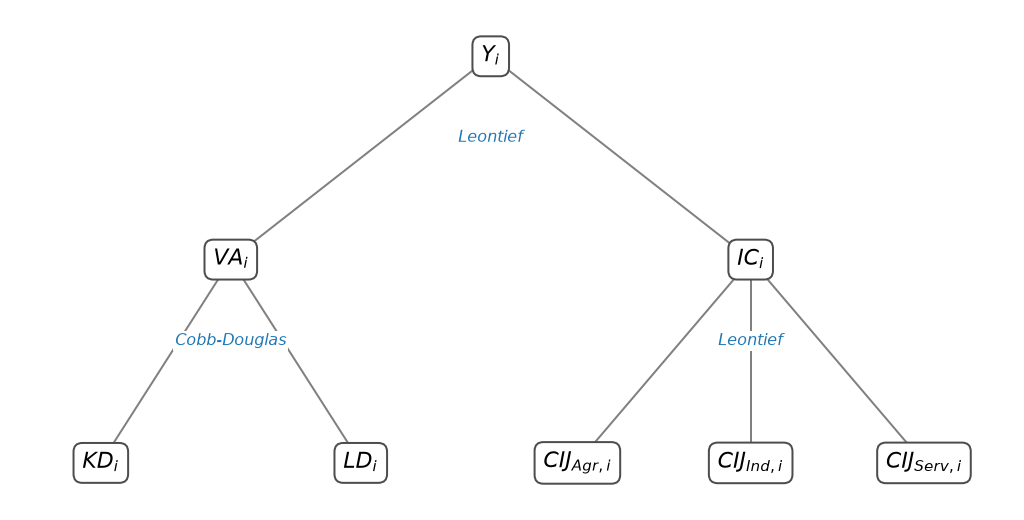

In [2]:
tree = nx.Graph([("$Y_i$", "$VA_i$"),
                 ("$Y_i$", "$IC_i$"),
                 ("$VA_i$", "$KD_i$"),
                 ("$VA_i$", "$LD_i$"),
                 ("$IC_i$", "$CIJ_{Agr,i}$"),
                 ("$IC_i$", "$CIJ_{Ind,i}$"),
                 ("$IC_i$", "$CIJ_{Serv,i}$")])
tree_positions = {"$Y_i$": (0.0, 2.0),
                  "$VA_i$": (-1.5, 1.0),
                  "$IC_i$": (1.5, 1.0),
                  "$KD_i$": (-2.25, 0.0),
                  "$LD_i$": (-0.75, 0.0),
                  "$CIJ_{Agr,i}$": (0.5, 0.0),
                  "$CIJ_{Ind,i}$": (1.5, 0.0),
                  "$CIJ_{Serv,i}$": (2.5, 0.0)}
nest_labels = {"$Y_i$": "Leontief", "$VA_i$": "Cobb-Douglas", "$IC_i$": "Leontief"}

fig, ax = plt.subplots(figsize=(7, 3.5),
                       dpi=144,
                       layout="constrained")
nx.draw_networkx_edges(tree,
                       pos=tree_positions,
                       ax=ax,
                       edge_color="0.5",
                       node_size=2500)
nx.draw_networkx_labels(tree,
                        pos=tree_positions,
                        ax=ax,
                        font_size=11,
                        bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "0.3"})
for node, label in nest_labels.items():
    x, y = tree_positions[node]
    ax.text(x,
            y - 0.4,
            label,
            ha="center",
            va="center",
            fontsize=8,
            color="C0",
            style="italic",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.0})
ax.set_axis_off()
plt.show()

### Variables

Sector-level objects are indexed by the sectors. A `CGEModel` takes the index labels as `coords`. Intermediate consumption $CIJ_{ij}$ needs two indices, the good bought and the sector buying it, so the model has a second coordinate `j` with the same three labels as `i`. A variable declared with `dims="i"` is a vector with one entry per sector.

Two prices are new compared with the first notebook. $PVA_i$ is the price of a unit of value added, and $PIC_i$ is the price of a unit of the intermediate bundle. Utility $U$ is also new. It plays no role in solving the model, but it measures the agent's welfare.

In [3]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Price of good <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Income of the agent")
    C = cm.Variable("C", dims="i", description="Consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of the agent")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

<IPython.core.display.Latex object>

### Parameters

Each sector has its own technology: a capital share $\alpha_i$ and productivity $A_i$ in value added, and fixed coefficients $\psi^{VA}_i$, $\psi^{IC}_i$ and $\psi^{IJC}_{ij}$ in the two Leontief nests. The agent spends a fixed share $\gamma_i$ of income on each good. The endowments $LS$ and $KS$ are parameters as before.

The numeraire also changes. The wage is now a variable, and the price of agriculture is held at the level $\bar P_{Agr}$. Only one element of the price vector $P$ is fixed, so $P$ stays a variable and a numeraire equation pins its agricultural entry to the parameter.

In [4]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Budget share of good <dim:i>")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    P_Agr = cm.Parameter("P_Agr", latex_name=r"\bar{P}_{Agr}", description="Price of agriculture, the numeraire")

mod.summary("parameters")

<IPython.core.display.Latex object>

### Equations

The production block has one equation per production variable. The two Leontief demands fix value added and the intermediate bundle as shares of output. Zero profit sets the value of output equal to the cost of its two inputs, so each good's price equals its average cost. The Cobb-Douglas block is the first notebook's production function and factor demands, now sector by sector. The intermediate price is the cost of the bundle at current goods prices, and the last Leontief demand splits the bundle into the three goods.

Income, demand and market clearing follow. Cobb-Douglas utility gives each good a fixed budget share. Labor and capital clear across the three sectors, and each good's output covers final consumption plus its use as an intermediate input everywhere. $Leon$ sits in the labor market as in the first notebook, and the last equation is the numeraire.

An expression combines indexed objects by their dimension names. `.sum("j")` sums over the buying sectors, `.rename(i="j")` relabels a sector-indexed vector as indexed by `j`, and `.sel(i="Agr")` picks one entry.

In [5]:
with mod:
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", P * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD, alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD, (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))
    cm.Equation("Income", INC, W * LS + R * KS)
    cm.Equation("Consumption", P * C, gamma * INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Labor market clearing", LS, LD.sum() + Leon)
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Goods market clearing", Y, C + CIJ.sum("j"))
    cm.Equation("Numeraire", P.sel(i="Agr"), P_Agr)

mod.equation_table()

<IPython.core.display.Latex object>

In [6]:
mod.compile();

Compiling a model with 41 equations, 41 variables, 27 parameters


The model has 41 equations in 41 variables. Without the numeraire equation, prices would be free to scale together as in the first notebook, and the labor market would be the redundant market that $Leon$ checks. The course fixes $P_{Agr}$ directly and reports 40 equations in 40 free variables. The two formulations are the same system.

## Data

The benchmark comes from a compact social accounting matrix (SAM). Rows receive and columns pay. The labor and capital rows hold each sector's factor payments, and the factors pay their income to the household account `Men` (*ménages*). The three goods rows show who buys each good: the household for final consumption, and the three sectors as intermediate inputs. Sector and good share one account each, so a sector's column total is its cost of production and the matching row total is the value of its output.

In [7]:
accounts = ["LD", "KD", "Men", *sectors]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1000.0, 2000.0, 4000.0]
sam.loc["KD", sectors] = [500.0, 2000.0, 500.0]
sam.loc["Men", ["LD", "KD"]] = [7000.0, 3000.0]
sam.loc[sectors, "Men"] = [2000.0, 2500.0, 5500.0]
sam.loc[sectors, sectors] = [[1000.0, 1000.0, 1000.0],
                             [2000.0, 3500.0, 3000.0],
                             [500.0, 2500.0, 1000.0]]

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,Men,Agr,Ind,Serv
LD,0.0,0.0,0.0,1000.0,2000.0,4000.0
KD,0.0,0.0,0.0,500.0,2000.0,500.0
Men,7000.0,3000.0,0.0,0.0,0.0,0.0
Agr,0.0,0.0,2000.0,1000.0,1000.0,1000.0
Ind,0.0,0.0,2500.0,2000.0,3500.0,3000.0
Serv,0.0,0.0,5500.0,500.0,2500.0,1000.0


## Calibration

The calibration normalizes five benchmark prices to 1: the goods prices $P_i$, the wage, the return to capital, and the two composite prices $PVA_i$ and $PIC_i$. Quantities then equal the values in the SAM.

The order is the same as in the first notebook. Factor demands and intermediate flows come from the SAM, and the endowments are their sums. Value added and the intermediate bundle add up each sector's purchases, and output is their total. Consumption is whatever output the sectors do not use as inputs. The share parameters come last, as ratios of benchmark values: $\alpha_i$ is capital's share of value added, the $\psi$ coefficients are input requirements per unit, and $\gamma_i$ is each good's share of income.

In [8]:
def calibrate_model(mod, *, LD, KD, CIJ):
    P = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0

    LS = LD.sum()
    KS = KD.sum()
    VA = (W * LD + R * KD) / PVA
    alpha = R * KD / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))
    INC = W * LS + R * KS
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC
    Y = (PVA * VA + PIC * IC) / P
    C = Y - CIJ.sum(axis=1)

    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]
    gamma = P * C / INC
    U = np.prod(C**gamma)
    Leon = LS - LD.sum()
    P_Agr = P[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    LD=sam.loc["LD", sectors].values,
                                    KD=sam.loc["KD", sectors].values,
                                    CIJ=sam.loc[sectors, sectors].values)

In [9]:
pd.DataFrame({name: calibrated_values[name] for name in ["VA", "IC", "Y", "C", "alpha", "gamma", "A"]},
             index=sectors).round(4)

,VA,IC,Y,C,alpha,gamma,A
Agr,1500.0,3500.0,5000.0,2000.0,0.3333,0.20,1.8899
Ind,4000.0,7000.0,11000.0,2500.0,0.5000,0.25,2.0000
Serv,4500.0,5000.0,9500.0,5500.0,0.1111,0.55,1.4174


In [10]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Capital supply +10%

The assignment asks for a 10% increase in labor supply and a 10% increase in capital supply. The correction solves the capital shock, so it comes first.

In [11]:
capital_shock = mod.simulate(initial_state=calibrated_values,
                             final_delta_pct={"KS": 1.1})
assert capital_shock["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||       Step         
 ───────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:01   0.00253855   18.01356883   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000003        4/    4

The course reports growth rates of output, consumption and prices sector by sector, of the two factor prices and income, and a Fisher consumer price index. The Fisher index is the geometric mean of a Laspeyres index (benchmark quantities) and a Paasche index (new quantities):

$$PIndC = 100 \sqrt{\frac{\sum_i P_i C_{0,i}}{\sum_i P_{0,i} C_{0,i}} \cdot \frac{\sum_i P_i C_i}{\sum_i P_{0,i} C_i}}.$$

The correction reports, for output, consumption and prices in agriculture, industry and services:

| | Agr | Ind | Serv |
|---|---|---|---|
| $Y$ growth (%) | 3.166 | 3.175 | 2.542 |
| $C$ growth (%) | 3.473 | 3.943 | 2.197 |
| $P$ growth (%) | 0 | -0.452 | 1.248 |

and growth of 3.918% in the wage, -6.877% in the return to capital and 3.473% in income, with $PIndC = 100.570$.

In [12]:
def growth(result, name):
    variables = result["optimizer"]["variables"]
    initial = variables[name].isel(step=0).values
    final = variables[name].isel(step=-1).values
    return 100 * (final / initial - 1)


def sector_growth(result):
    return pd.DataFrame({f"{name} growth (%)": growth(result, name) for name in ["Y", "C", "P"]},
                        index=sectors).T


def aggregate_growth(result):
    variables = result["optimizer"]["variables"]
    benchmark_prices = variables["P"].isel(step=0).values
    benchmark_consumption = variables["C"].isel(step=0).values
    prices = variables["P"].isel(step=-1).values
    consumption = variables["C"].isel(step=-1).values

    laspeyres = (prices * benchmark_consumption).sum() / (benchmark_prices * benchmark_consumption).sum()
    paasche = (prices * consumption).sum() / (benchmark_prices * consumption).sum()

    return pd.Series({"W growth (%)": growth(result, "W"),
                      "R growth (%)": growth(result, "R"),
                      "INC growth (%)": growth(result, "INC"),
                      "PIndC": 100 * np.sqrt(laspeyres * paasche)})


sector_growth(capital_shock).round(3)

,Agr,Ind,Serv
Y growth (%),3.166,3.175,2.542
C growth (%),3.473,3.943,2.197
P growth (%),0.000,-0.452,1.248


In [13]:
aggregate_growth(capital_shock).round(3)

W growth (%)        3.918
R growth (%)       -6.877
INC growth (%)      3.473
PIndC             100.570
dtype: float64

In [14]:
float(capital_shock["optimizer"]["variables"]["Leon"].isel(step=-1))

-6.920158403426496e-13

Every number matches the correction to three decimals, and $Leon$ is zero up to floating-point error.

More capital makes capital cheaper relative to labor: the return to capital falls by 6.9% and the wage rises by 3.9%. A sector's cost moves with the factor it uses most. Industry is the most capital-intensive sector ($\alpha = 0.5$), so its price falls relative to agriculture. Services is the most labor-intensive ($\alpha = 1/9$), so its price rises. Consumers shift toward the good that got cheaper: consumption grows most in industry and least in services.

Agricultural consumption grows at exactly the rate of income, 3.473%. Cobb-Douglas utility fixes the budget share of every good, and the agricultural price is the numeraire, so spending on agriculture and its quantity both grow with income.

## Labor supply +10%

The correction does not solve the labor shock. The tables below are new results from the same model.

In [15]:
labor_shock = mod.simulate(initial_state=calibrated_values,
                           final_delta_pct={"LS": 1.1})
assert labor_shock["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||       Step         
 ───────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:01   0.00310322   27.49747253   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000002        4/    4

In [16]:
sector_growth(labor_shock).round(3)

,Agr,Ind,Serv
Y growth (%),6.603,6.591,7.245
C growth (%),6.288,5.798,7.600
P growth (%),0.000,0.463,-1.220


In [17]:
aggregate_growth(labor_shock).round(3)

W growth (%)      -3.791
R growth (%)       7.356
INC growth (%)     6.288
PIndC             99.442
dtype: float64

In [18]:
float(labor_shock["optimizer"]["variables"]["Leon"].isel(step=-1))

4.995999684049411e-14

The labor shock reverses the capital shock. Labor gets cheaper relative to capital, so the labor-intensive services sector gets cheaper and grows fastest, and industry gets more expensive. Income grows by 6.3%, against 3.5% after the capital shock. Labor earns 70% of value added, so 10% more labor adds more output than 10% more capital.

## Prices and the capital-labor ratio

Both shocks change one thing that matters for prices: the ratio of capital to labor. Every technology has constant returns to scale and the agent's demand is homothetic, so scaling both endowments together would scale every quantity and leave relative prices unchanged. Relative prices therefore depend only on $\frac{KS}{LS}$.

The cell below checks this with the model. It sweeps capital supply and, separately, labor supply from half to double the benchmark, and records the goods prices along each path. Each sweep solves the model exactly at half the benchmark, then runs one Euler path to double it, solving exactly every 50 steps with `solve_every`. Both sweeps are plotted against the capital-labor ratio they produce.

In [19]:
def price_path(parameter):
    """Return goods prices along a path as one endowment moves from half to double its benchmark."""
    halved = mod.simulate(initial_state=calibrated_values,
                          final_delta_pct={parameter: 0.5},
                          progressbar=False)
    euler = mod.simulate(initial_state=halved,
                         final_values={parameter: 2.0 * float(np.asarray(calibrated_values[parameter]))},
                         n_iter_euler=1500,
                         solve_every=50,
                         use_optimizer=False,
                         progressbar=False)["euler"]
    capital_labor_ratio = euler["parameters"]["KS"].values / euler["parameters"]["LS"].values
    prices = pd.DataFrame(euler["variables"]["P"].values, columns=sectors)
    prices.insert(0, "KS/LS", capital_labor_ratio)
    return prices


price_paths = {"KS": price_path("KS"), "LS": price_path("LS")}

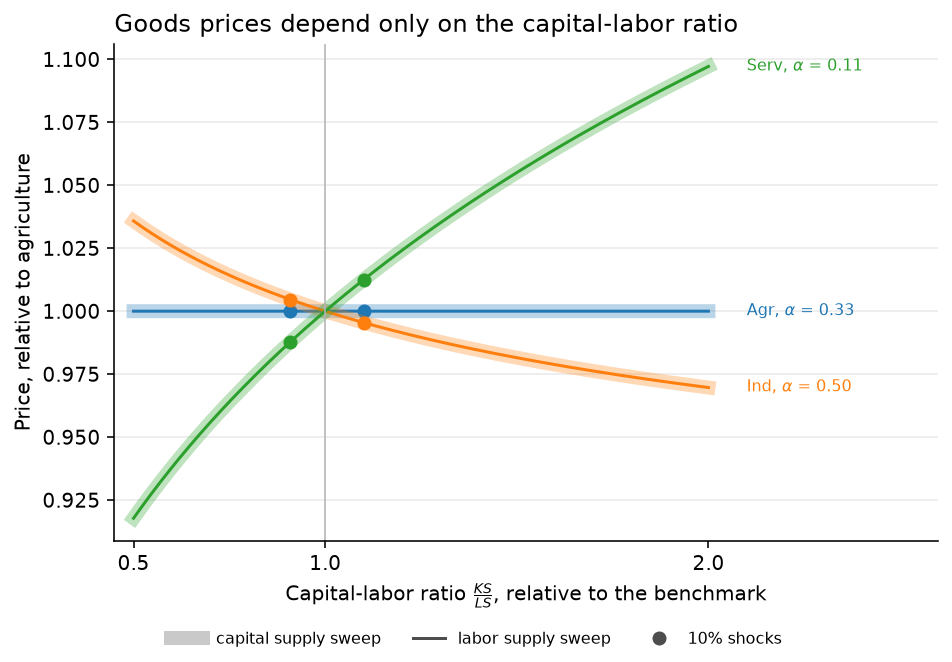

In [20]:
benchmark_ratio = float(calibrated_values["KS"] / calibrated_values["LS"])
sweep_styles = {"KS": {"linewidth": 7.0, "alpha": 0.3, "label": "capital supply sweep"},
                "LS": {"linewidth": 1.5, "alpha": 1.0, "label": "labor supply sweep"}}
shocks = [(capital_shock, 1.1), (labor_shock, 1 / 1.1)]

fig, ax = plt.subplots(figsize=(6.5, 4.5),
                       dpi=144,
                       layout="constrained")
for number, sector in enumerate(sectors):
    color = f"C{number}"
    for parameter, style in sweep_styles.items():
        path = price_paths[parameter]
        ax.plot(path["KS/LS"] / benchmark_ratio,
                path[sector],
                color=color,
                linewidth=style["linewidth"],
                alpha=style["alpha"])
    for result, ratio in shocks:
        ax.plot(ratio,
                float(result["optimizer"]["variables"]["P"].isel(step=-1).sel(i=sector)),
                marker="o",
                color=color)
    ax.text(2.1,
            float(price_paths["KS"][sector].iloc[-1]),
            f"{sector}, $\\alpha$ = {float(calibrated_values['alpha'][number]):.2f}",
            va="center",
            fontsize=8,
            color=color)

for style in sweep_styles.values():
    ax.plot([],
            [],
            color="0.3",
            linewidth=style["linewidth"],
            alpha=style["alpha"],
            label=style["label"])
ax.plot([],
        [],
        color="0.3",
        marker="o",
        linestyle="none",
        label="10% shocks")
ax.axvline(1.0,
           color="0.7",
           linewidth=0.8)
ax.set(xlim=(0.45, 2.6),
       xlabel=r"Capital-labor ratio $\frac{KS}{LS}$, relative to the benchmark",
       ylabel="Price, relative to agriculture")
ax.set_title("Goods prices depend only on the capital-labor ratio",
             loc="left")
ax.minorticks_off()
ax.set_xticks([0.5, 1.0, 2.0])
ax.grid(axis="y",
        color="0.92")
ax.spines[["top", "right"]].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

The two sweeps trace the same curves, and each 10% shock lands on them: the capital shock at a ratio of 1.1 and the labor shock at 1/1.1. Which endowment moved does not matter, only how the ratio changed.

Agriculture is the numeraire, so its line is flat by construction. The other two prices order by capital intensity. As capital becomes more abundant, industry, which uses more capital per unit of value added than agriculture, gets cheaper, and services, which uses less, gets more expensive. Each good's cost also includes intermediate inputs bought from all three sectors, so its price reflects the factor intensity of those suppliers as well as its own $\alpha_i$.

## Authors

- Created by Jesse Grabowski, November 25, 2026

## Watermark

In [21]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
networkx    : 3.6.1
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

